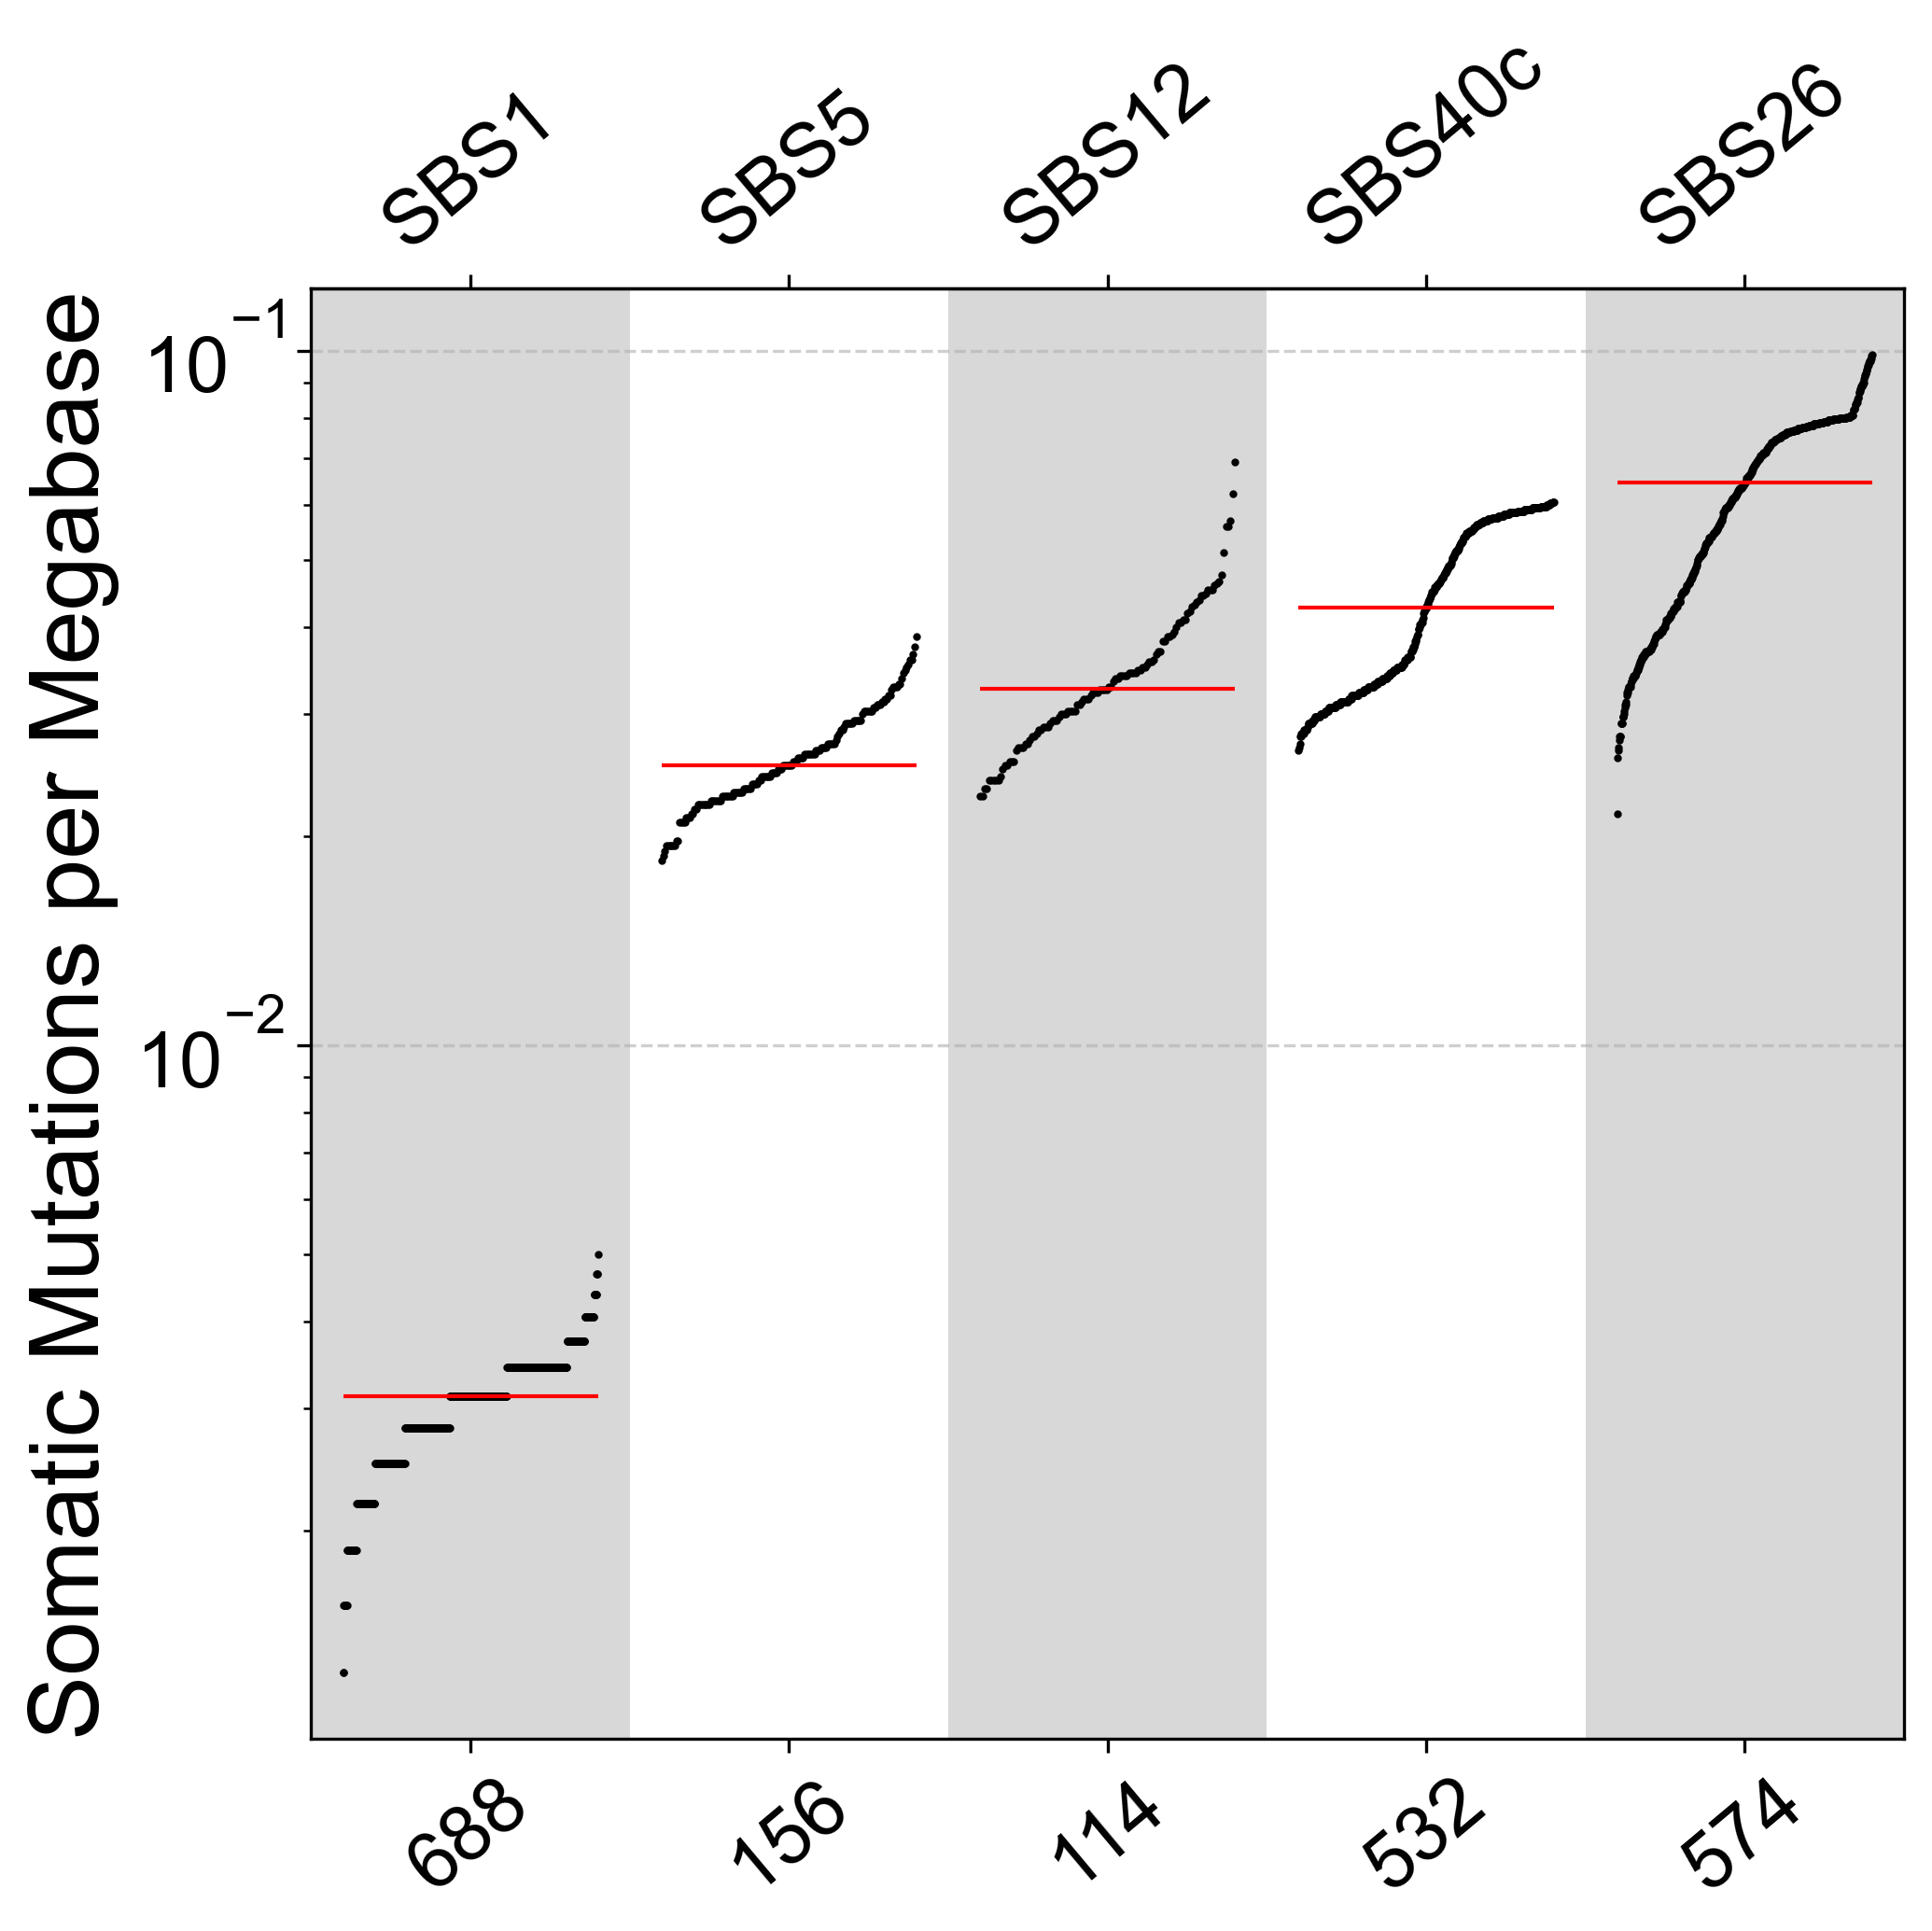

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = 'Arial'

# Make results folder
os.makedirs("results", exist_ok=True)

# ---- PARAMETERS ----
GENOME_SIZE_MB = 3200  # adjust depending on WGS/WES/panel
MIN_CELL_FRACTION = 0.10  # 10% threshold

# ---- LOAD DATA ----
df = pd.read_csv(
    "../just_leaves/example_vcf_per_cell/Assignment_Solution/Activities/Assignment_Solution_Activities.txt",
    sep="\t"
)

df = df.set_index("Samples")

# Remove signatures with all zeros
df = df.loc[:, (df != 0).any(axis=0)]

# Remove signatures in <10% of cells
cell_threshold = int(len(df) * MIN_CELL_FRACTION)
df = df.loc[:, (df > 0).sum(axis=0) >= cell_threshold]

# Normalize to mutations per megabase
df = df / GENOME_SIZE_MB

# Compute median of nonzero values
nonzero_medians = df.apply(lambda col: col[col > 0].median(), axis=0)

# Sort signatures by nonzero median
df = df[nonzero_medians.sort_values().index]

# ---- PLOT ----
fig, ax = plt.subplots(figsize=(7, 7), dpi=300)  # higher resolution

for i, sig in enumerate(df.columns, start=1):
    values = df[sig].values
    values = values[values > 0]
    values = np.sort(values)

    if len(values) > 0:
        x_positions = np.linspace(i - 0.4, i + 0.4, len(values))
        ax.scatter(x_positions, values, color="black", s=1, zorder=3)
        ax.hlines(np.median(values), i - 0.4, i + 0.4, colors="red", lw=1, zorder=4)

# Add alternating grey background
for i in range(1, len(df.columns) + 1, 2):
    ax.axvspan(i - 0.5, i + 0.5, facecolor="grey", alpha=0.3, zorder=0)

# Y-axis
ax.set_yscale("log")
ax.set_ylabel("Somatic Mutations per Megabase", fontsize=25)
ax.tick_params(axis="y", labelsize=20)  # increase y-axis tick font
ax.grid(axis="y", linestyle="--", alpha=0.6, zorder=0)

# Bottom x-axis → number of samples with >0 mutations
counts = (df > 0).sum(axis=0).values
ax.set_xticks(range(1, len(df.columns) + 1))
ax.set_xticklabels(counts, rotation=40, ha="center", fontsize=20)

# Top x-axis → signature names
ax_top = ax.secondary_xaxis("top")
ax_top.set_xticks(range(1, len(df.columns) + 1))
ax_top.set_xticklabels(df.columns, rotation=40, fontsize=20)

# Remove first and last column space
ax.set_xlim(0.5, len(df.columns) + 0.5)

plt.tight_layout()
plt.savefig("results/mutations_per_mb_per_cell.pdf", format="pdf")  # save as high-res PDF
plt.show()


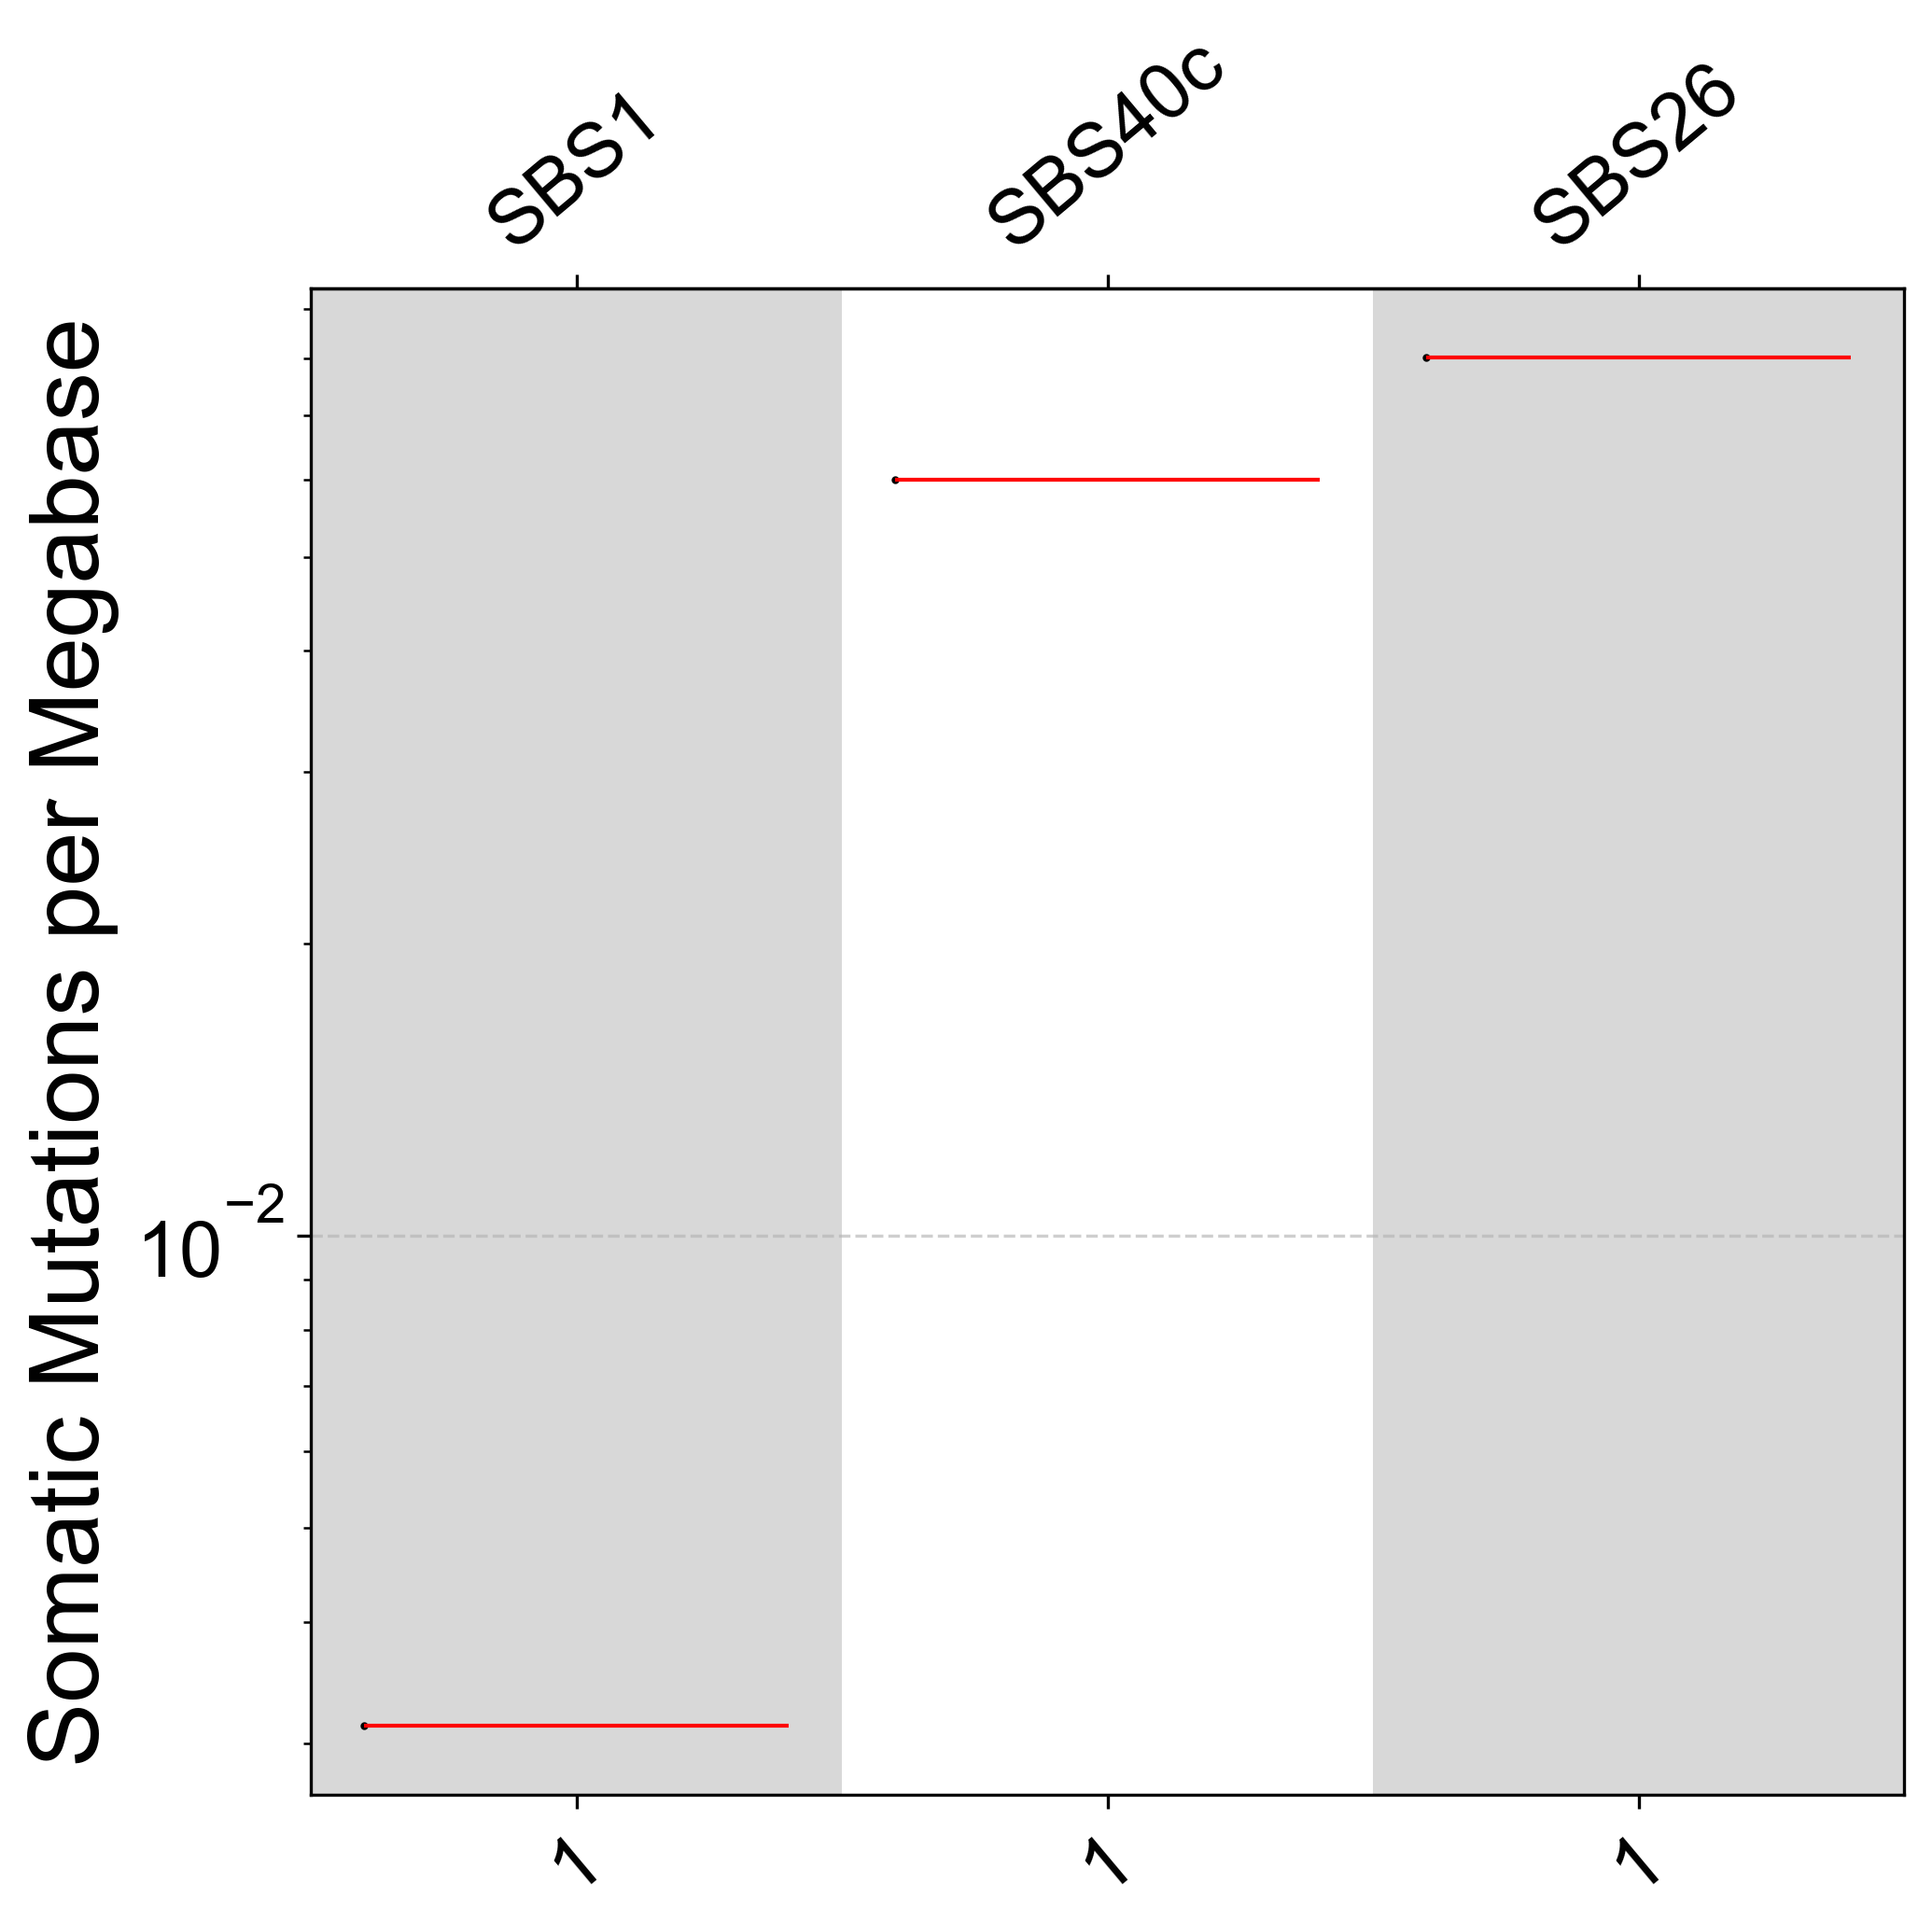

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = 'Arial'

# Make results folder
os.makedirs("results", exist_ok=True)

# ---- PARAMETERS ----
GENOME_SIZE_MB = 3200  # adjust depending on WGS/WES/panel
MIN_CELL_FRACTION = 0.10  # 10% threshold

# ---- LOAD DATA ----
df = pd.read_csv(
    "../just_leaves/example_vcf_all/Assignment_Solution/Activities/Assignment_Solution_Activities.txt",
    sep="\t"
)

df = df.set_index("Samples")

# Remove signatures with all zeros
df = df.loc[:, (df != 0).any(axis=0)]

# Remove signatures in <10% of cells
cell_threshold = int(len(df) * MIN_CELL_FRACTION)
df = df.loc[:, (df > 0).sum(axis=0) >= cell_threshold]

# Normalize to mutations per megabase
df = df / GENOME_SIZE_MB

# Compute median of nonzero values
nonzero_medians = df.apply(lambda col: col[col > 0].median(), axis=0)

# Sort signatures by nonzero median
df = df[nonzero_medians.sort_values().index]

# ---- PLOT ----
fig, ax = plt.subplots(figsize=(7, 7), dpi=300)  # higher resolution

for i, sig in enumerate(df.columns, start=1):
    values = df[sig].values
    values = values[values > 0]
    values = np.sort(values)

    if len(values) > 0:
        x_positions = np.linspace(i - 0.4, i + 0.4, len(values))
        ax.scatter(x_positions, values, color="black", s=1, zorder=3)
        ax.hlines(np.median(values), i - 0.4, i + 0.4, colors="red", lw=1, zorder=4)

# Add alternating grey background
for i in range(1, len(df.columns) + 1, 2):
    ax.axvspan(i - 0.5, i + 0.5, facecolor="grey", alpha=0.3, zorder=0)

# Y-axis
ax.set_yscale("log")
ax.set_ylabel("Somatic Mutations per Megabase", fontsize=25)
ax.tick_params(axis="y", labelsize=20)  # increase y-axis tick font
ax.grid(axis="y", linestyle="--", alpha=0.6, zorder=0)

# Bottom x-axis → number of samples with >0 mutations
counts = (df > 0).sum(axis=0).values
ax.set_xticks(range(1, len(df.columns) + 1))
ax.set_xticklabels(counts, rotation=40, ha="center", fontsize=20)

# Top x-axis → signature names
ax_top = ax.secondary_xaxis("top")
ax_top.set_xticks(range(1, len(df.columns) + 1))
ax_top.set_xticklabels(df.columns, rotation=40, fontsize=20)

# Remove first and last column space
ax.set_xlim(0.5, len(df.columns) + 0.5)

plt.tight_layout()
plt.savefig("results/mutations_per_mb_all.pdf", format="pdf")  # save as high-res PDF
plt.show()
